# 2017 Sparse MoE：从稀疏路由到条件计算

本 notebook 是 [Shazeer 等人（2017）](https://arxiv.org/abs/1701.06538) 核心机制的**单 GPU、小模型实验**。它不复现论文的语言模型、翻译任务或多机并行；要验证的是下面这条链：

$$
\text{增加 Expert 数 }N\Rightarrow\text{总参数增长};\qquad
\text{固定 Top-}K\Rightarrow\text{每个 token 只执行 }K\text{ 个 Expert};\qquad
\text{负载均衡损失}\Rightarrow\text{避免少数 Expert 独占 token}.
$$

**需要回答的四个问题**

1. 真正的 `dispatch → Expert → combine` 能否与“全部 Expert 计算后乘稀疏 gate”得到相同的输出和梯度？
2. 固定 $K=2$ 时，增加 $N$ 是否使总参数增加，而每个 token 的 Expert 算术量保持不变？真实 GPU 推理延迟是否也保持不变？
3. Noisy Top-K 的 importance/load 辅助损失分别怎样改变实际负载？
4. Router 的路由与隐藏数据模式是否相关，同时没有让多数 Expert 闲置？

**边界**：这里的“计算量不变”只指 Expert 的理论计算量。Router 要为 $N$ 个 Expert 打分，分发与小批次计算有额外开销；实际推理时间由后面的 GPU 计时给出，不能预先假定不变。

| 实验 | 对照 | 验证内容 |
| --- | --- | --- |
| 实现正确性 | 全量 Expert 版 vs 真稀疏版，同参数、同路由 | 输出与梯度等价；执行次数从 $TN$ 变为 $TK$ |
| 均衡消融 | Full / 无辅助损失 / 仅 importance / 仅 load | MSE、gate mass、实际 Top-K 负载、Expert 闲置 |
| 容量扫描 | $N=4,8,16$，固定 $K$ 和单 Expert 大小 | 总参数、激活计算、任务误差 |
| 推理基准 | $N=4,8,16,32$，稀疏版 vs 全量版 | GPU 延迟、吞吐、不同 token 数下的开销 |
| Dense 对照 | 匹配总参数量 / 匹配每 token 的 Expert 计算量 | 分开比较“容量”与“计算预算” |

运行环境：`conda activate pytorch`，必须有 CUDA GPU。按从上到下的顺序执行。默认配置偏向可在小显卡上完成；正式结论仍需要更多种子和任务重复。

## 1. 数据与任务：八条明确的分段回归规则

**一个 token 究竟是什么？** 隐藏组别 $g\in\{0,1,\ldots,7\}$ 先被均匀抽出，然后生成一个 **6 维**连续输入：前 2 维 $m=(m_1,m_2)$ 是带噪声的组别线索，后 4 维 $u=(u_1,u_2,u_3,u_4)$ 是回归函数真正使用的数值输入，拼接为 $x=(m,u)\in\mathbb R^6$。前两维**不是**直接给模型的类别 ID 或 one-hot 标签；模型必须从坐标位置推断组别。

$$
g\sim\operatorname{Uniform}\{0,\ldots,7\},\qquad
m\mid g\sim\mathcal N(c_g,\sigma^2I_2),\qquad
u\sim\mathcal N(0,I_4),\qquad
x=(m,u),\quad y=f_g(u).
$$

八个中心 $c_g=(2.5\cos(2\pi g/8),\,2.5\sin(2\pi g/8))$ 分布在圆周上；$\sigma=0.45$。**真值函数如下，每组固定一条线性规则**：

$$
\begin{aligned}
f_0(u)&= 1.2u_1+0.4u_2-0.6u_3+0.2u_4+0.2,\\
f_1(u)&=-0.8u_1+1.1u_2+0.3u_3-0.5u_4-0.3,\\
f_2(u)&= 0.5u_1-1.3u_2+0.9u_3+0.4u_4+0.1,\\
f_3(u)&=-1.1u_1-0.6u_2+0.2u_3+1.0u_4-0.2,\\
f_4(u)&= 0.7u_1+0.8u_2-1.0u_3-0.4u_4+0.4,\\
f_5(u)&=-0.3u_1+0.5u_2+1.2u_3-0.9u_4-0.4,\\
f_6(u)&= 1.0u_1-0.9u_2-0.4u_3+0.7u_4+0.3,\\
f_7(u)&=-0.7u_1-0.2u_2+0.8u_3+1.1u_4-0.1.
\end{aligned}
$$

例如隐藏组别为 3 时，先在中心 $c_3$ 附近采样前两维，再独立采样四维 $u$，最后用**编号为 3 的规则** $f_3(u)$ 计算标签。例如 $u=(1,2,-1,0.5)$ 时，$y=-1.1(1)-0.6(2)+0.2(-1)+1.0(0.5)-0.2=-2.2$；前两维标记的噪声不会直接进入这条真值公式。模型训练时只拿到 $x$ 和 $y$，拿不到 $g$；因此它必须同时学会“由 $m$ 判断应使用哪条规则”和“根据 $u$ 计算该规则的输出”。训练每步重新采样，评估使用全新 token。这里的序列维度仅模拟 token batch，没有 Attention 或位置交互。

相邻的组别线索有重叠，给定同一个 $x$ 时组别可能不确定。由于生成规律已知，评估额外计算 Bayes 参考预测：

$$
f^*(x)=\sum_{g=0}^{7}P(g\mid m)f_g(u).
$$

这个参考值帮助区分模型学习不足与数据本身的组别不确定性。

In [1]:
import math
import statistics
import time
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "本实验按 GPU 设计：请 conda activate pytorch 并检查 CUDA。"
DEVICE = torch.device("cuda")
print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

# 小模型主体；性能测试稍后单独使用中等维度，以减少 Python/索引开销占比。
D_MODEL, D_FF, NUM_GROUPS = 6, 16, 8
TOP_K, MAIN_EXPERTS = 2, 8
BATCH_SIZE, SEQ_LEN = 128, 16
TRAIN_STEPS, LR = 1200, 2e-3
FEATURE_STD = 0.45
LAMBDA_IMPORTANCE = LAMBDA_LOAD = 0.05
EVAL_TOKENS = 16384
MAIN_SEED = 42

# 数据生成器的维度约定：T 表示本次生成的 token 总数；输入为 [T, 6]，标签为 [T, 1]。
# 前两列 m 是组别线索，后四列 u 才进入每组的真值函数。
angles = torch.arange(NUM_GROUPS, device=DEVICE) * (2 * math.pi / NUM_GROUPS)
# angles: [8]；cos/sin 堆叠后得到 8 个二维圆周中心 [8, 2]。
CENTERS = 2.5 * torch.stack([angles.cos(), angles.sin()], dim=-1)
# 每行按 (u1,u2,u3,u4) 排列，与上方 f_0,...,f_7 逐项对应。
TEACHER_W = torch.tensor([
    [ 1.2,  0.4, -0.6,  0.2],
    [-0.8,  1.1,  0.3, -0.5],
    [ 0.5, -1.3,  0.9,  0.4],
    [-1.1, -0.6,  0.2,  1.0],
    [ 0.7,  0.8, -1.0, -0.4],
    [-0.3,  0.5,  1.2, -0.9],
    [ 1.0, -0.9, -0.4,  0.7],
    [-0.7, -0.2,  0.8,  1.1],
], device=DEVICE)
TEACHER_B = torch.tensor([0.2, -0.3, 0.1, -0.2, 0.4, -0.4, 0.3, -0.1], device=DEVICE)
assert TEACHER_W.shape == (NUM_GROUPS, D_MODEL - 2)


def make_batch(tokens, generator, std=FEATURE_STD):
    # 每个 token 独立抽一个隐藏组别，group: [T]；该整数不输入模型。
    group = torch.randint(NUM_GROUPS, (tokens,), device=DEVICE, generator=generator)
    # 用 group 索引中心：CENTERS[group] 为 [T, 2]；加同形状高斯噪声得到标记 m。
    marker = CENTERS[group] + std * torch.randn(tokens, 2, device=DEVICE, generator=generator)
    # u: [T, 4]，与组别独立；每组规则 f_g 都以这四个数为输入。
    payload = torch.randn(tokens, D_MODEL - 2, device=DEVICE, generator=generator)
    # 在最后一维拼接 [T, 2] 和 [T, 4]，形成模型真正看到的 x: [T, 6]。
    x = torch.cat([marker, payload], dim=-1)
    # TEACHER_W[group]: [T, 4]；逐元素乘积后沿四个 u 维求和，得到 [T, 1]。
    # TEACHER_B[group, None]: [T, 1]，逐 token 加上所属组的固定偏置。
    y = (payload * TEACHER_W[group]).sum(-1, keepdim=True) + TEACHER_B[group, None]
    return x, group, y


def bayes_predict(x, std=FEATURE_STD):
    # 从 x: [T, 6] 拆出 m: [T, 2] 和 u: [T, 4]。
    marker, payload = x[:, :2], x[:, 2:]
    # marker[:, None, :]: [T, 1, 2]，CENTERS[None, :, :]: [1, 8, 2]。
    # 广播相减得到每个 token 到 8 个中心的距离 [T, 8, 2]；平方求和后为 [T, 8]。
    log_p = -((marker[:, None, :] - CENTERS[None, :, :]) ** 2).sum(-1) / (2 * std ** 2)
    # 组别先验相同，因此对 8 个对数似然做 softmax 得 P(g|m): [T, 8]。
    p_group = log_p.softmax(-1)
    # u:[T,4] @ W.T:[4,8]，一次算出每个 token 在全部 8 条规则下的输出 [T,8]。
    each_target = payload @ TEACHER_W.T + TEACHER_B
    # 以 P(g|m) 加权求和，Bayes 预测为 [T,1]；这里的真值系数只用于评估基准。
    return (p_group * each_target).sum(-1, keepdim=True)

rng = torch.Generator(device=DEVICE).manual_seed(2026)
example_x, example_group, example_y = make_batch(5, rng)
print("x", tuple(example_x.shape), "g", tuple(example_group.shape), "y", tuple(example_y.shape))

PyTorch: 2.5.1 | GPU: NVIDIA GeForce GTX 1050 Ti
x (5, 6) g (5,) y (5, 1)


### 数据可视化：组别线索与八条真值函数

真值函数的输入 $u=(u_1,u_2,u_3,u_4)$ 是四维的，不能完整画在二维纸面上。下图使用两个明确的**截面**：

- 左图显示前两维 $m$ 的采样分布及八个中心。颜色来自生成器的隐藏组别，仅用于检查数据；Router 训练时看不到这些颜色或标签。
- 右图固定 $u_2=u_3=u_4=0$，横轴改变 $u_1$，得到八条 $f_g(u_1,0,0,0)$。不同斜率和截距说明各组要拟合不同的规律。
- 第二张图固定 $u_3=u_4=0$，对每组分别画 $f_g(u_1,u_2,0,0)$ 的二维热力图。颜色范围全图一致，便于比较。它仍只是四维函数的截面；$u_3,u_4$ 的作用由上面的完整公式给出。

**这里的“分段”是由隐藏组别 $g$ 选择八条函数之一**；前两维只是带噪声的组别线索，不是精确的分段边界。

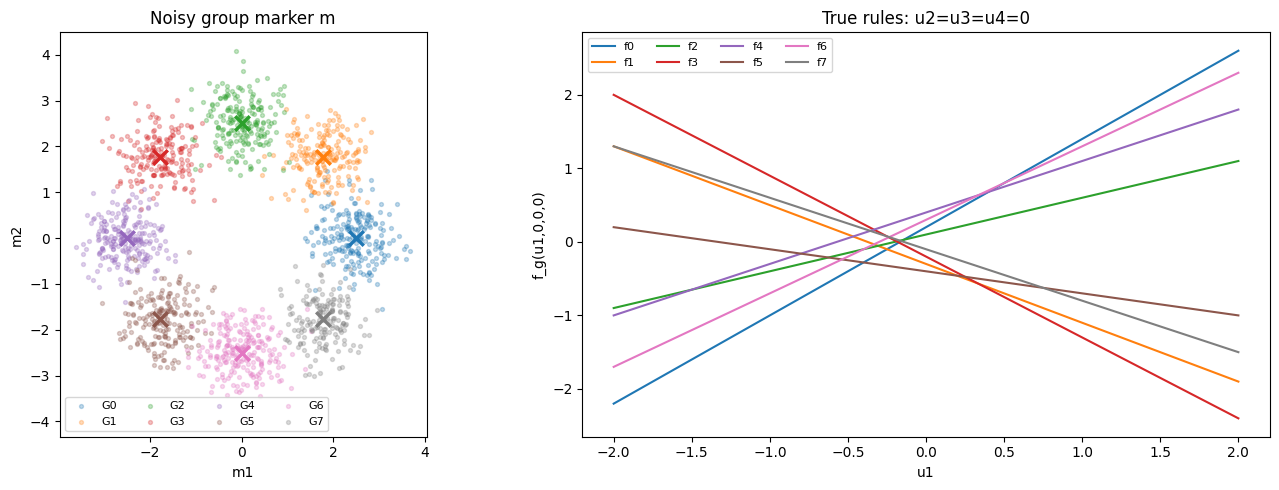

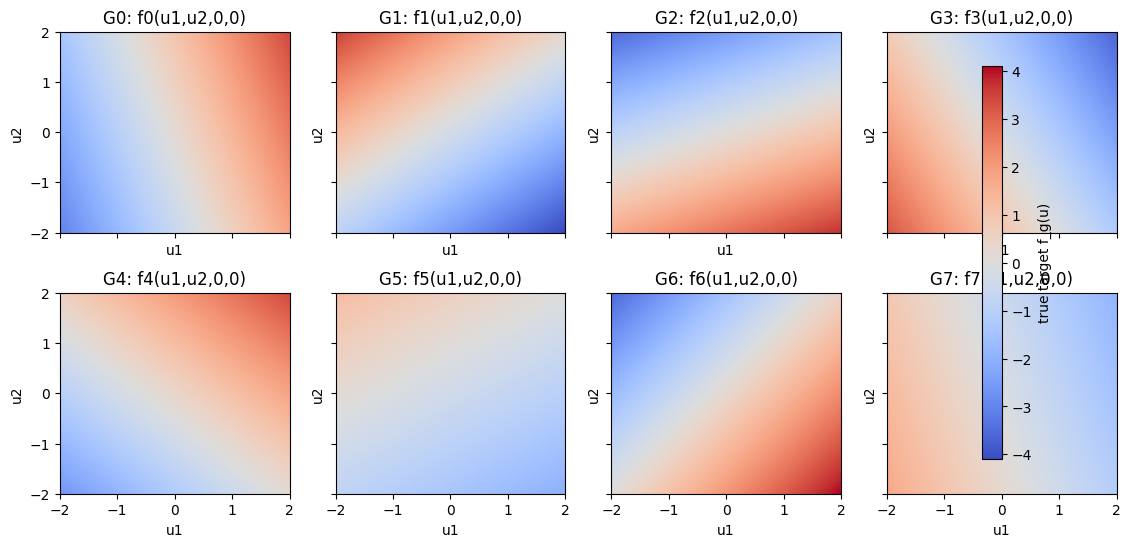

In [2]:
# 只用于展示数据；独立随机生成器不改变后面训练和评估所用的随机流。
plot_rng = torch.Generator(device=DEVICE).manual_seed(31415)
plot_x, plot_group, _ = make_batch(1600, plot_rng)
plot_m = plot_x[:, :2].cpu().numpy()       # [1600, 2]：用于识别组别的连续标记
plot_g = plot_group.cpu().numpy()           # [1600]：只用于给数据图上色
centers_np = CENTERS.cpu().numpy()          # [8, 2]：八个组中心

# 一维函数截面：[301, 4] 中只有 u1 改变，矩阵乘法一次得到 [301, 8] 条函数值。
u1 = torch.linspace(-2.0, 2.0, 301, device=DEVICE)
u_slice = torch.zeros(u1.numel(), D_MODEL - 2, device=DEVICE)
u_slice[:, 0] = u1
y_slice = (u_slice @ TEACHER_W.T + TEACHER_B).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.get_cmap("tab10").colors
for g in range(NUM_GROUPS):
    mask = plot_g == g
    axes[0].scatter(plot_m[mask, 0], plot_m[mask, 1], s=8, alpha=0.28,
                    color=colors[g], label=f"G{g}")
    axes[0].scatter(*centers_np[g], marker="x", s=110, linewidths=2.5,
                    color=colors[g])
    axes[1].plot(u1.cpu().numpy(), y_slice[:, g], color=colors[g], label=f"f{g}")
axes[0].set(title="Noisy group marker m", xlabel="m1", ylabel="m2", aspect="equal")
axes[0].legend(ncol=4, fontsize=8)
axes[1].set(title="True rules: u2=u3=u4=0", xlabel="u1", ylabel="f_g(u1,0,0,0)")
axes[1].legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

# 二维函数截面：网格 [81,81] -> 展平 [6561,4]，一次算出八组输出 [6561,8]。
axis = torch.linspace(-2.0, 2.0, 81, device=DEVICE)
grid_u1, grid_u2 = torch.meshgrid(axis, axis, indexing="ij")
u_plane = torch.zeros(axis.numel() ** 2, D_MODEL - 2, device=DEVICE)
u_plane[:, 0] = grid_u1.reshape(-1)
u_plane[:, 1] = grid_u2.reshape(-1)
plane_values = (u_plane @ TEACHER_W.T + TEACHER_B).reshape(81, 81, NUM_GROUPS)
plane_values = plane_values.cpu().numpy()   # [81,81,8]；最后一维是组别
color_limit = float(np.max(np.abs(plane_values)))

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for g, ax in enumerate(axes.flat):
    # 行索引对应 u1、列索引对应 u2；转置后图中横轴为 u1、纵轴为 u2。
    image = ax.imshow(plane_values[:, :, g].T, origin="lower", extent=(-2, 2, -2, 2),
                      vmin=-color_limit, vmax=color_limit, cmap="coolwarm", aspect="auto")
    ax.set_title(f"G{g}: f{g}(u1,u2,0,0)")
    ax.set_xlabel("u1")
    ax.set_ylabel("u2")
fig.colorbar(image, ax=axes.ravel().tolist(), label="true target f_g(u)", shrink=0.85)
fig.subplots_adjust(wspace=0.2, hspace=0.3, right=0.88)
plt.show()

## 2. 模型：Noisy Top-2 与真正的 token dispatch

Router 对每个 token 产生基础分数 $\mu\in\mathbb R^N$ 和正噪声尺度 $s\in\mathbb R^N$：

$$
\mu=W_gx+b_g,\quad s=\operatorname{softplus}(W_nx+b_n)+\epsilon,\quad
H_i=\begin{cases}\mu_i+s_i\varepsilon_i,&\text{训练}\; (\varepsilon_i\sim\mathcal N(0,1))\\\mu_i,&\text{推理}\end{cases}
$$

只在 $H$ 的前 $K$ 个值上做 softmax，得到非零 gate $a_i$。每个 Expert 是独立的 `6 → 16 → 1` MLP，MoE 预测为 $\hat y=\sum_{i\in\operatorname{TopK}(H)}a_iE_i(x)$。Router 两个矩阵置零初始化，使初期负载近似均衡；这一做法也见于论文的负载均衡附录。这里不用 LayerNorm，以保留用于识别组别的前两维绝对位置。

`forward_sparse` 将 token 按 Expert 收集，只执行选中的 Expert；`forward_dense_reference` 则执行全部 Expert，仅用于核对与计时对照。两者共用 Router、Expert 和 gate。单机 PyTorch 版本仍会对 Expert 做 Python 循环；它验证条件计算，**不等同于高性能分布式 MoE 内核**。

In [3]:
# 下文统一记：T=token 数，D=输入维度，N=Expert 数，K=每 token 选中的 Expert 数。
class Expert(nn.Module):
    def __init__(self, d_model=D_MODEL, d_ff=D_FF):
        super().__init__()
        # 一个 Expert 独立实现 [T_i,D] -> [T_i,d_ff] -> [T_i,1]；T_i 是分给它的 token 数。
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, 1))

    def forward(self, x):
        return self.net(x)


class NoisyTopKRouter(nn.Module):
    def __init__(self, d_model, n_experts, k=TOP_K):
        super().__init__()
        assert 1 <= k < n_experts
        self.n_experts, self.k = n_experts, k
        # 两个线性层都把 [T,D] 映射为 [T,N]：一个给均值，一个给噪声尺度。
        self.gate = nn.Linear(d_model, n_experts)
        self.noise = nn.Linear(d_model, n_experts)
        # 零初始化使初始 clean logits 一致，训练噪声帮助各 Expert 获得样本。
        nn.init.zeros_(self.gate.weight)
        nn.init.zeros_(self.gate.bias)
        nn.init.zeros_(self.noise.weight)
        nn.init.zeros_(self.noise.bias)

    def forward(self, x, fixed_noise=None):
        # x:[T,D] -> mu:[T,N]，每行是一个 token 对 N 个 Expert 的基础分数。
        mu = self.gate(x)
        # 同形状 [T,N]；softplus 保证噪声标准差为正。
        sigma = F.softplus(self.noise(x)) + 1e-4
        # 仅训练时加逐 token、逐 Expert 的独立高斯噪声；推理固定用 mu。
        if self.training:
            eps = torch.randn_like(mu) if fixed_noise is None else fixed_noise
            logits = mu + sigma * eps
        else:
            logits = mu
        # 沿 Expert 维取前 K：分数与 Expert 编号均为 [T,K]。
        top_values, top_indices = logits.topk(self.k, dim=-1)
        # 只在被选中的 K 个 Expert 之间归一化，权重 [T,K]，每行之和为 1。
        top_weights = top_values.softmax(-1)
        # 把 K 个权重写回 [T,N]；其他 N-K 个位置严格为零。
        gates = torch.zeros_like(logits).scatter(-1, top_indices, top_weights)
        return gates, top_indices, top_weights, mu, sigma, logits


class SparseMoE(nn.Module):
    def __init__(self, n_experts=MAIN_EXPERTS, d_model=D_MODEL, d_ff=D_FF, k=TOP_K):
        super().__init__()
        self.n_experts, self.k = n_experts, k
        self.router = NoisyTopKRouter(d_model, n_experts, k)
        self.experts = nn.ModuleList([Expert(d_model, d_ff) for _ in range(n_experts)])

    def forward_sparse(self, x, fixed_noise=None):
        # gates:[T,N]；indices/weights:[T,K]；不需要先计算全部 Expert。
        gates, indices, weights, mu, sigma, logits = self.router(x, fixed_noise)
        # 每个 (token, Top-K slot) 只出现一次；index_add 汇总同一 token 的两路输出。
        output = x.new_zeros(x.size(0), 1)
        for expert_id, expert in enumerate(self.experts):
            # 比较矩阵 [T,K] 中等于当前 Expert 的位置。
            # token_id 和 slot 都是 [T_i]；slot 指该 Expert 是第几个 Top-K 选择。
            token_id, slot = torch.where(indices == expert_id)
            if token_id.numel() == 0:
                continue
            # 收集当前 Expert 的输入：[T,D] -> [T_i,D]，只对这些 token 执行它。
            expert_x = x.index_select(0, token_id)
            # Expert 输出 [T_i,1]，选中权重 weights[token_id,slot,None] 为 [T_i,1]。
            contribution = expert(expert_x) * weights[token_id, slot, None]
            # 按原 token 编号加回 [T,1]；同一 token 的 K 路贡献被求和。
            output = output.index_add(0, token_id, contribution)
        return output, gates, indices, mu, sigma, logits

    def forward_dense_reference(self, x, fixed_noise=None):
        gates, indices, _, mu, sigma, logits = self.router(x, fixed_noise)
        # 教学参照：每个 Expert 都看全部 T 个 token；堆叠 [T,1,N] 再去掉标量输出维得 [T,N]。
        every_output = torch.stack([expert(x) for expert in self.experts], dim=-1).squeeze(1)
        # gates:[T,N] 逐元素乘 Expert 输出 [T,N]，沿 N 求和恢复 [T,1]。
        output = (gates * every_output).sum(-1, keepdim=True)
        return output, gates, indices, mu, sigma, logits

    def forward(self, x, fixed_noise=None):
        return self.forward_sparse(x, fixed_noise)


def parameter_count(model):
    return sum(p.numel() for p in model.parameters())

print("main MoE parameters:", parameter_count(SparseMoE().to(DEVICE)))

main MoE parameters: 1144


### 实现核对：输出、梯度和计算次数

两版使用相同参数与同一张 `fixed_noise`，因此 Top-K 完全一致。检查参数梯度的目的，是发现 token 索引或加权合并错误。全量版执行 $TN$ 条 token–Expert 路径，稀疏版只执行 $TK$ 条；这里的“次数”是模型实际传给 Expert 的 token 数，不是 GPU 时间。

In [4]:
torch.manual_seed(7)
check_model = SparseMoE().to(DEVICE).train()
check_rng = torch.Generator(device=DEVICE).manual_seed(8)
check_x, _, check_y = make_batch(256, check_rng)
# 固定 [T,N] 路由噪声，保证稀疏版和全量版使用完全相同的 Top-K。
fixed_noise = torch.randn(256, MAIN_EXPERTS, device=DEVICE)

def check_gradients(model, x, y, noise, sparse):
    model.zero_grad(set_to_none=True)
    result = model.forward_sparse(x, noise) if sparse else model.forward_dense_reference(x, noise)
    F.mse_loss(result[0], y).backward()
    # 复制每个参数的梯度；未被某一路径使用的参数按零梯度处理。
    grads = {name: p.grad.detach().clone() if p.grad is not None else torch.zeros_like(p)
             for name, p in model.named_parameters()}
    return result[0].detach(), result[2].detach(), grads

sparse_y, sparse_idx, sparse_grads = check_gradients(check_model, check_x, check_y, fixed_noise, True)
full_y, full_idx, full_grads = check_gradients(check_model, check_x, check_y, fixed_noise, False)
output_error = (sparse_y - full_y).abs().max().item()
grad_error = max((sparse_grads[name] - full_grads[name]).abs().max().item() for name in sparse_grads)
assert torch.equal(sparse_idx, full_idx)
assert torch.allclose(sparse_y, full_y, atol=1e-5, rtol=1e-5)
assert all(torch.allclose(sparse_grads[name], full_grads[name], atol=1e-5, rtol=1e-4)
           for name in sparse_grads)
print(f"max |output diff|={output_error:.3e}; max |gradient diff|={grad_error:.3e}")
print(f"T={len(check_x)}: sparse {len(check_x)*TOP_K} vs full {len(check_x)*MAIN_EXPERTS} token–Expert executions")

max |output diff|=0.000e+00; max |gradient diff|=1.490e-08
T=256: sparse 512 vs full 2048 token–Expert executions


## 3. 损失：任务、Importance 与 Smooth Load

$$
L_{task}=\operatorname{MSE}(\hat y,y),\qquad
I_i=\sum_t a_{t,i},\qquad L_{importance}=\operatorname{CV}^2(I),
\quad \operatorname{CV}^2(v)=\frac{\operatorname{Var}(v)}{\operatorname{Mean}(v)^2+\epsilon}.
$$

实际入选次数 $\sum_t\mathbf1[i\in\operatorname{TopK}(H_t)]$ 不适合直接反向传播。对每个 Expert，取其他 Expert 的第 $K$ 大 noisy logit 作为阈值 $T_{t,i}$，计算其条件入选概率：

$$
p_{t,i}=\Phi\left(\frac{\mu_{t,i}-T_{t,i}}{s_{t,i}}\right),\quad
L_i=\sum_t p_{t,i},\quad L_{load}=\operatorname{CV}^2(L),
\quad L=L_{task}+\lambda_I L_{importance}+\lambda_L L_{load}.
$$

代码通过一次 `topk(K+1)` 得到各 Expert 所需的阈值，用 `erf` 计算标准正态 CDF。这是对采样路由条件下负载的**平滑估计**；推理时不加噪声，因此最终实际负载以 hard count 为准。训练日志里若某一损失系数为零，该项仍计算并记录诊断值，不以零冒充实测负载。

In [5]:
def cv2(v):
    return v.var(unbiased=False) / (v.mean().square() + 1e-8)


def router_losses(gates, mu, sigma, noisy_logits, k=TOP_K):
    # gates:[T,N] 沿 token 维求和，importance:[N]。
    importance = gates.sum(0)
    n = mu.shape[-1]
    # 每个 token 取第 1 到第 K+1 大的分数与编号，均为 [T,K+1]。
    top = noisy_logits.topk(k + 1, dim=-1)
    in_topk = torch.zeros_like(noisy_logits, dtype=torch.bool)
    # 将 [T,K] 的已入选编号写入布尔矩阵 [T,N]。
    in_topk.scatter_(1, top.indices[:, :k], True)
    # 对 i 排除自身：当前入选用原排序第 K+1 大，否则用第 K 大。
    threshold = torch.where(in_topk, top.values[:, k:k+1], top.values[:, k-1:k])
    # threshold 是 [T,N]；mu、sigma 同形，逐项标准化得到 z:[T,N]。
    z = (mu - threshold) / sigma
    # erf 实现标准正态 CDF；p_in[t,i] 是条件入选概率，形状 [T,N]。
    p_in = 0.5 * (1 + torch.erf(z / math.sqrt(2)))
    # 沿 T 求和得到每个 Expert 的平滑负载 [N]。
    smooth_load = p_in.sum(0)
    return cv2(importance), cv2(smooth_load), importance, smooth_load


def hard_load(indices, n_experts):
    # indices:[T,K] 展平为 [T*K] 个实际分配编号，再计数得到 [N]。
    return torch.bincount(indices.reshape(-1), minlength=n_experts)

# sanity checks: 每个 token 的 gate 和为 1，非零数为 K。
with torch.no_grad():
    check_model.eval()
    _, gate_test, idx_test, _, _, _ = check_model(check_x)
    assert torch.allclose(gate_test.sum(-1), torch.ones(len(check_x), device=DEVICE))
    assert torch.all((gate_test > 0).sum(-1) == TOP_K)
    assert hard_load(idx_test, MAIN_EXPERTS).sum().item() == len(check_x) * TOP_K
print("gate、Top-K 和 hard load 检查通过")

gate、Top-K 和 hard load 检查通过


## 4. 训练与评估函数

所有模型统一训练 **1200 步**；每一步在线重新采样。相同种子的消融使用相同初始化和数据流。评估生成器独立固定，使模型面对同一批新 token。

为区分训练与推理负载，评估时对**同一批评估输入**运行两遍：训练模式保留 Noisy Top-K，使用固定随机噪声；推理模式关闭噪声，使用 clean logits。分别报告两种模式的实际 hard Top-K 负载、最大/平均负载及近闲置 Expert 数；MSE、gate 热力图和互信息使用真正的推理模式。这里的“训练模式负载”只模拟训练时的路由机制，不对评估样本反向传播或更新参数。

In [6]:
def make_eval_data(tokens=EVAL_TOKENS):
    generator = torch.Generator(device=DEVICE).manual_seed(20261004)
    return make_batch(tokens, generator)

# 固定独立评估集：x:[EVAL_TOKENS,6]，组别:[EVAL_TOKENS]，目标:[EVAL_TOKENS,1]。
EVAL_X, EVAL_GROUP, EVAL_Y = make_eval_data()
with torch.inference_mode():
    BAYES_MSE = F.mse_loss(bayes_predict(EVAL_X), EVAL_Y).item()
print(f"Bayes reference MSE on evaluation sample: {BAYES_MSE:.6f}")


def train_moe(n_experts, seed, steps=TRAIN_STEPS, lambda_i=LAMBDA_IMPORTANCE,
              lambda_l=LAMBDA_LOAD, verbose=False):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = SparseMoE(n_experts=n_experts).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    # 数据生成器与模型初始化分开；同一 seed 的不同消融看到同一批次序列。
    data_rng = torch.Generator(device=DEVICE).manual_seed(10000 + seed)
    history = defaultdict(list)
    for step in range(steps):
        model.train()
        # 每步在线采样 T=BATCH_SIZE*SEQ_LEN 个 token：x:[T,6]，y:[T,1]。
        x, _, y = make_batch(BATCH_SIZE * SEQ_LEN, data_rng)
        # 稀疏前向预测 [T,1]；Router 的四组统计张量分别为 [T,N] 或 [T,K]。
        prediction, gates, indices, mu, sigma, logits = model(x)
        task = F.mse_loss(prediction, y)
        loss_i, loss_l, _, _ = router_losses(gates, mu, sigma, logits)
        # 三个标量损失相加；即使某系数为 0，也保留诊断统计。
        loss = task + lambda_i * loss_i + lambda_l * loss_l
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if step % 50 == 0 or step == steps - 1:
            history["step"].append(step + 1)
            history["mse"].append(task.item())
            history["importance_cv2"].append(loss_i.item())
            history["load_cv2"].append(loss_l.item())
            if verbose and (step % 150 == 0 or step == steps - 1):
                print(f"N={n_experts} step={step+1:4d}: MSE={task.item():.4f}, "
                      f"importance={loss_i.item():.3f}, load={loss_l.item():.3f}")
    return model, dict(history)


def evaluate_moe(model):
    n = model.n_experts
    with torch.inference_mode():
        # 推理路径：关闭噪声，在固定的新样本上报告最终预测质量和 clean hard load。
        model.eval()
        yhat, gates, indices, _, _, _ = model(EVAL_X)
        mse = F.mse_loss(yhat, EVAL_Y).item()
        counts = hard_load(indices, n).float()  # [T,K] -> [N]
        load_share = counts / counts.sum()
        gate_mass = gates.mean(0)               # [T,N] -> [N]

        # 用同一评估输入模拟训练时的 Noisy Top-K；固定 [T,N] 噪声保证可重复。
        noise_rng = torch.Generator(device=DEVICE).manual_seed(20261004 + n)
        fixed_noise = torch.randn(len(EVAL_X), n, generator=noise_rng, device=DEVICE)
        model.train()
        _, noisy_gates, noisy_indices, noisy_mu, noisy_sigma, noisy_logits = model(
            EVAL_X, fixed_noise=fixed_noise
        )
        noisy_counts = hard_load(noisy_indices, n).float()
        noisy_load_share = noisy_counts / noisy_counts.sum()
        _, _, _, smooth_load = router_losses(noisy_gates, noisy_mu, noisy_sigma, noisy_logits)
        smooth_load_share = smooth_load / smooth_load.sum()
        model.eval()  # 恢复推理状态，供后续调用。

        # one_hot 转置为 [G,T]，乘 clean gates:[T,N] 得各组累计 gate mass [G,N]。
        group_onehot = F.one_hot(EVAL_GROUP, NUM_GROUPS).float()
        group_gate = group_onehot.T @ gates
        group_gate /= torch.bincount(EVAL_GROUP, minlength=NUM_GROUPS)[:, None]
        # 全体 token 归一化后形成联合分布 P(g,e):[G,N]，用于互信息。
        joint = group_onehot.T @ gates / len(EVAL_X)
        pg = joint.sum(1, keepdim=True)  # [G,1]
        pe = joint.sum(0, keepdim=True)  # [1,N]
        mi = (joint * ((joint + 1e-9).log() - (pg @ pe + 1e-9).log())).sum().item()
        group_mse = torch.zeros(NUM_GROUPS, device=DEVICE)
        for g in range(NUM_GROUPS):
            mask = EVAL_GROUP == g
            group_mse[g] = F.mse_loss(yhat[mask], EVAL_Y[mask])
    # 数值和数组转到 CPU，供后续表格与 Matplotlib 绘图使用。
    return dict(
        mse=mse, excess_mse=mse-BAYES_MSE, mi=mi,
        gate_mass=gate_mass.cpu(), group_gate=group_gate.cpu(), group_mse=group_mse.cpu(),
        load_share=load_share.cpu(), max_mean_load=(counts.max()/counts.mean()).item(),
        near_idle=int((load_share < 0.01).sum().item()),
        noisy_load_share=noisy_load_share.cpu(), noisy_gate_mass=noisy_gates.mean(0).cpu(),
        smooth_load_share=smooth_load_share.cpu(),
        noisy_max_mean_load=(noisy_counts.max()/noisy_counts.mean()).item(),
        noisy_near_idle=int((noisy_load_share < 0.01).sum().item()),
    )

class DenseBaseline(nn.Module):
    # Dense 对照只使用输入 x:[T,6]，输出 [T,1]，没有 Router。
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(D_MODEL, width), nn.GELU(), nn.Linear(width, 1))

    def forward(self, x):
        return self.net(x)


def train_dense(width, seed=MAIN_SEED, steps=TRAIN_STEPS):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = DenseBaseline(width).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    data_rng = torch.Generator(device=DEVICE).manual_seed(10000 + seed)
    history = defaultdict(list)
    for step in range(steps):
        model.train()
        x, _, y = make_batch(BATCH_SIZE * SEQ_LEN, data_rng)
        loss = F.mse_loss(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if step % 50 == 0 or step == steps - 1:
            history["step"].append(step + 1)
            history["mse"].append(loss.item())
    model.eval()
    with torch.inference_mode():
        mse = F.mse_loss(model(EVAL_X), EVAL_Y).item()
    return model, dict(history), mse

Bayes reference MSE on evaluation sample: 0.187017


## 5. 消融实验：两个均衡损失各自做了什么？

固定 $N=8,K=2$，四个模型都训练 1200 步。对同一新样本同时检查带噪声训练模式与无噪声推理模式的 **hard Top-K 负载**。辅助损失训练的是带噪声路由的 gate mass 和 smooth load，因而推理负载不一定与之相同；两个模式必须分开解释。MSE 与分工热力图按无噪声推理模式计算。

In [7]:
# 四种损失配置共享 N=8、K=2、1200 步训练与相同种子的在线数据流。
ABLATIONS = {
    "Full": (LAMBDA_IMPORTANCE, LAMBDA_LOAD),
    "No balance": (0.0, 0.0),
    "Importance only": (LAMBDA_IMPORTANCE, 0.0),
    "Load only": (0.0, LAMBDA_LOAD),
}
models, histories, stats = {}, {}, {}
for name, (li, ll) in ABLATIONS.items():
    print("training", name, flush=True)
    models[name], histories[name] = train_moe(MAIN_EXPERTS, MAIN_SEED,
                                              lambda_i=li, lambda_l=ll)
    stats[name] = evaluate_moe(models[name])
print(f"{'Model':<18} {'MSE':>8} {'MI':>7} {'Clean max/mean':>15} {'Noisy max/mean':>15} "
      f"{'Clean idle':>11} {'Noisy idle':>11}")
for name, s in stats.items():
    print(f"{name:<18} {s['mse']:8.4f} {s['mi']:7.3f} "
          f"{s['max_mean_load']:15.3f} {s['noisy_max_mean_load']:15.3f} "
          f"{s['near_idle']:11d} {s['noisy_near_idle']:11d}")

training Full


training No balance


training Importance only


training Load only


Model                   MSE      MI  Clean max/mean  Noisy max/mean  Clean idle  Noisy idle
Full                 0.2437   1.227           1.406           1.399           0           0
No balance           0.2450   1.010           1.972           1.943           3           2
Importance only      0.2504   1.128           1.859           1.826           1           1
Load only            0.2407   1.184           1.521           1.523           0           0


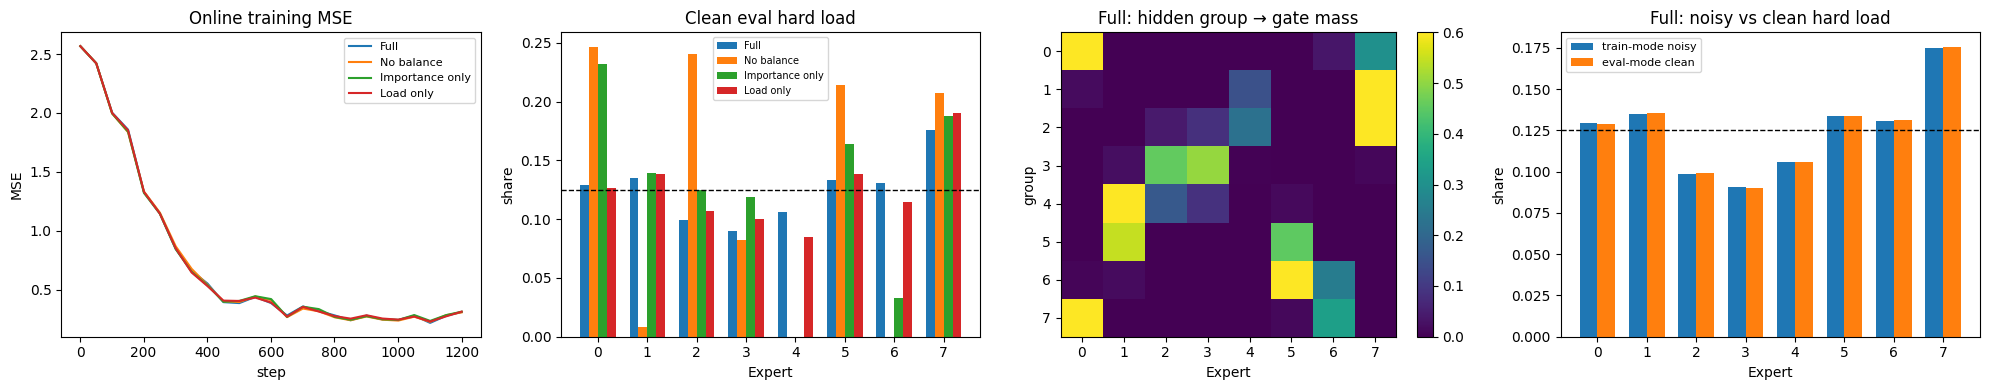

Full               noisy hard=[0.13  0.135 0.099 0.091 0.106 0.134 0.131 0.175] clean hard=[0.129 0.135 0.099 0.09  0.106 0.134 0.131 0.176] smooth=[0.13  0.135 0.098 0.09  0.107 0.134 0.131 0.175]
No balance         noisy hard=[0.243 0.012 0.237 0.082 0.    0.214 0.004 0.207] clean hard=[0.247 0.008 0.241 0.082 0.    0.214 0.    0.207] smooth=[0.243 0.012 0.237 0.083 0.001 0.214 0.003 0.208]
Importance only    noisy hard=[0.228 0.139 0.124 0.118 0.    0.164 0.039 0.188] clean hard=[0.232 0.139 0.125 0.119 0.    0.164 0.033 0.188] smooth=[0.228 0.139 0.125 0.118 0.    0.164 0.039 0.188]
Load only          noisy hard=[0.127 0.138 0.107 0.1   0.084 0.139 0.114 0.19 ] clean hard=[0.126 0.139 0.107 0.1   0.085 0.138 0.114 0.19 ] smooth=[0.127 0.138 0.107 0.1   0.084 0.139 0.114 0.19 ]


In [8]:
# 四幅图：训练 MSE、四种消融的 clean hard load、组别路由、Full 的 noisy/clean 负载。
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for name, h in histories.items():
    axes[0].plot(h["step"], h["mse"], label=name)
axes[0].set(title="Online training MSE", xlabel="step", ylabel="MSE")
axes[0].legend(fontsize=8)

xpos = np.arange(MAIN_EXPERTS)
width = 0.18
for j, name in enumerate(ABLATIONS):
    axes[1].bar(xpos + (j-1.5)*width, stats[name]["load_share"].numpy(), width, label=name)
axes[1].axhline(1/MAIN_EXPERTS, color="black", ls="--", lw=1)
axes[1].set(title="Clean eval hard load", xlabel="Expert", ylabel="share", xticks=xpos)
axes[1].legend(fontsize=7)

# group_gate:[G,N]；行是隐藏组别，列是 Expert，颜色是平均 gate mass。
im = axes[2].imshow(stats["Full"]["group_gate"].numpy(), aspect="auto", vmin=0, vmax=0.6)
axes[2].set(title="Full: hidden group → gate mass", xlabel="Expert", ylabel="group",
            xticks=xpos, yticks=np.arange(NUM_GROUPS))
fig.colorbar(im, ax=axes[2])

# 同一批输入、同一模型；只切换 Router 的噪声模式。
axes[3].bar(xpos-0.18, stats["Full"]["noisy_load_share"].numpy(), 0.36, label="train-mode noisy")
axes[3].bar(xpos+0.18, stats["Full"]["load_share"].numpy(), 0.36, label="eval-mode clean")
axes[3].axhline(1/MAIN_EXPERTS, color="black", ls="--", lw=1)
axes[3].set(title="Full: noisy vs clean hard load", xlabel="Expert", ylabel="share", xticks=xpos)
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

for name in ABLATIONS:
    s=stats[name]
    print(f"{name:<18} noisy hard={np.round(s['noisy_load_share'].numpy(), 3)} "
          f"clean hard={np.round(s['load_share'].numpy(), 3)} "
          f"smooth={np.round(s['smooth_load_share'].numpy(), 3)}")

### 多种子复核

单个种子无法支持负载均衡的普遍结论。Full 与无均衡版本各用三个种子完整训练 1200 步；报告 MSE 与 noisy/clean 两种最大负载比的均值和样本标准差。其余两种单独损失消融保留一次运行，用于机制观察。

In [9]:
# 主种子 42 的统计已在上面得到；再训练种子 43、44。
seed_check = {"Full": [stats["Full"]], "No balance": [stats["No balance"]]}
for seed in (43, 44):
    for name in seed_check:
        li, ll = ABLATIONS[name]
        print(f"seed check: {name}, seed={seed}", flush=True)
        model_check, _ = train_moe(MAIN_EXPERTS, seed, lambda_i=li, lambda_l=ll)
        seed_check[name].append(evaluate_moe(model_check))
for name, runs in seed_check.items():
    mses = [r["mse"] for r in runs]
    clean_ratios = [r["max_mean_load"] for r in runs]
    noisy_ratios = [r["noisy_max_mean_load"] for r in runs]
    print(f"{name:<12} MSE={statistics.mean(mses):.4f}±{statistics.stdev(mses):.4f}; "
          f"clean max/mean={statistics.mean(clean_ratios):.3f}±{statistics.stdev(clean_ratios):.3f}; "
          f"noisy max/mean={statistics.mean(noisy_ratios):.3f}±{statistics.stdev(noisy_ratios):.3f}; "
          f"clean idle={[r['near_idle'] for r in runs]}")

seed check: Full, seed=43


seed check: No balance, seed=43


seed check: Full, seed=44


seed check: No balance, seed=44


Full         MSE=0.2407±0.0069; clean max/mean=1.297±0.104; noisy max/mean=1.290±0.107; clean idle=[0, 0, 0]
No balance   MSE=0.2427±0.0055; clean max/mean=1.881±0.251; noisy max/mean=1.870±0.236; clean idle=[3, 3, 0]


## 6. 容量扫描与两种 Dense 对照

固定任务、$K=2$ 和单个 Expert 的 `6 → 16 → 1` 结构，比较 $N=4,8,16$。**每个容量运行三个相同种子，并且全部训练 1200 步**；图表报告 MSE 的均值和标准差，避免将某次的 8/16 Expert 微小差异视为确定趋势。每个 token 的理论 Expert 乘加数约为 $K(6\times16+16\times1)=224$，与 $N$ 无关；总参数则随 $N$ 增加。

Dense 的 `6 → width → 1`：`width≈K×16=32` 近似匹配每 token Expert 算术量；另一宽度近似匹配 $N=8$ MoE 的总参数。两种 Dense 对照也各运行三个相同种子、1200 步。Router 和分发的额外计算没有计入这里的 Expert MAC，但会反映在实际计时中。

training capacity N=4, seed=42


training capacity N=4, seed=43


training capacity N=4, seed=44


training capacity N=16, seed=42


training capacity N=16, seed=43


...

training Dense compute, seed=43


training Dense params, seed=43


training Dense compute, seed=44


training Dense params, seed=44


Model                    Params  Expert MAC/token     Eval MSE mean±SD
MoE N=4                     572               224   0.2844±0.0493
MoE N=8                    1144               224   0.2407±0.0069
MoE N=16                   2288               224   0.2530±0.0050
Dense compute               257               224   0.3653±0.0140
Dense params               1145              1001   0.3142±0.0032


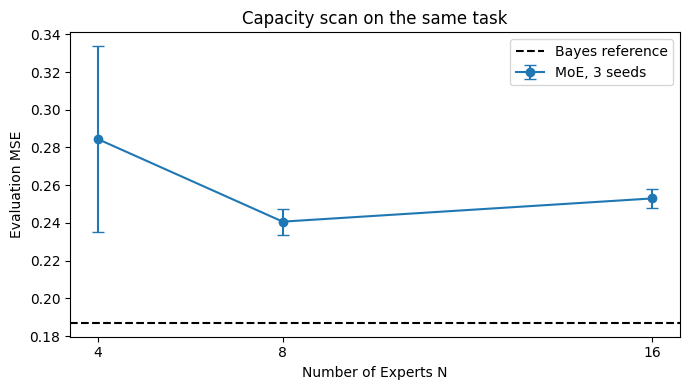

In [10]:
# 容量扫描：N=8 的三个 Full 结果复用前面的三个种子，避免重复训练。
CAPACITY_SEEDS = (42, 43, 44)
capacity_models = {8: models["Full"]}  # 保留主种子模型用于参数量统计。
capacity_runs = {8: list(seed_check["Full"]), 4: [], 16: []}
for n in (4, 16):
    for seed in CAPACITY_SEEDS:
        print(f"training capacity N={n}, seed={seed}", flush=True)
        model_capacity, _ = train_moe(n, seed)
        if seed == MAIN_SEED:
            capacity_models[n] = model_capacity
        capacity_runs[n].append(evaluate_moe(model_capacity))

# Dense 每 token MAC 约为 (D+1)*width；取 width=K*d_ff 匹配 MoE Expert MAC。
compute_width = TOP_K * D_FF
# Dense 总参数为 (D+2)*width+1；反解 width 近似匹配 N=8 MoE 总参数。
param_width = round((parameter_count(models["Full"]) - 1) / (D_MODEL + 2))
dense_runs = {"compute": [], "params": []}
dense_models = {}
for seed in CAPACITY_SEEDS:
    for label, width in (("compute", compute_width), ("params", param_width)):
        print(f"training Dense {label}, seed={seed}", flush=True)
        dense_model, _, dense_mse = train_dense(width, seed=seed)
        if seed == MAIN_SEED:
            dense_models[label] = dense_model
        dense_runs[label].append(dense_mse)

print(f"{'Model':<22} {'Params':>8} {'Expert MAC/token':>17} {'Eval MSE mean±SD':>20}")
for n in (4, 8, 16):
    mses = [s["mse"] for s in capacity_runs[n]]
    print(f"MoE N={n:<16} {parameter_count(capacity_models[n]):8d} "
          f"{TOP_K*(D_MODEL*D_FF+D_FF):17d} "
          f"{statistics.mean(mses):8.4f}±{statistics.stdev(mses):.4f}")
for label, width in (("compute", compute_width), ("params", param_width)):
    mses = dense_runs[label]
    print(f"Dense {label:<16} {parameter_count(dense_models[label]):8d} "
          f"{(D_MODEL+1)*width:17d} "
          f"{statistics.mean(mses):8.4f}±{statistics.stdev(mses):.4f}")

# 容量图同时画出误差条和 Bayes 参考；误差条表示三个种子的样本标准差。
fig, ax = plt.subplots(figsize=(7, 4))
ns = [4, 8, 16]
means = [statistics.mean(s["mse"] for s in capacity_runs[n]) for n in ns]
sds = [statistics.stdev(s["mse"] for s in capacity_runs[n]) for n in ns]
ax.errorbar(ns, means, yerr=sds, fmt="o-", capsize=4, label="MoE, 3 seeds")
ax.axhline(BAYES_MSE, color="black", ls="--", label="Bayes reference")
ax.set(title="Capacity scan on the same task", xlabel="Number of Experts N",
       ylabel="Evaluation MSE", xticks=ns)
ax.legend()
plt.tight_layout()
plt.show()

## 7. 推理速度实验：容量增长是否影响真实延迟？

**待检验假设**：固定 $K$ 与单 Expert 大小时，Expert 理论计算不随 $N$ 增长，但端到端延迟可能增长。为了把计时与任务拟合质量分开，本节使用同结构的随机模型和固定随机输入。性能模型为 `64 → 128 → 1`，最大 $N=32$ 时约 27 万参数，仍属小模型。

比较四条完整推理路径：

- **逐 Expert 稀疏版**：训练所用的易读实现，按 Expert 做 Python 循环；
- **批量打包稀疏版**：先按 Expert 排序，把 token 放入 `[N, capacity, D]`，用 `bmm` 批量执行所有 Expert，再加权合并；每次 forward 都计算本次实际最大负载来确定 capacity，不丢 token；
- **全量计算参照版**：每个 Expert 对所有 token 执行前向（Python 循环）；
- **批量全量版**：也用 `bmm` 处理所有 Expert，作为与批量打包稀疏版算子形态更接近的性能对照。

批量打包版的 Expert 权重只在进入推理模式时堆叠一次，和一般推理部署中的参数准备相同；**批量稀疏计时包含 Router、排序、动态 capacity、分发、Expert 计算与合并**。改变权重后需重新准备打包参数。三版对同一输入的输出必须一致。分别测 **1、256、2048 token**。CUDA event 预热后重复计时，报告中位数；推理时不加路由噪声。

这里的稀疏 `bmm` 使用最大 Expert 负载作为矩形容量，存在 padding 计算：物理执行的 Expert 槽位数为 `N × capacity`，可能大于真正的 `T × K` 条路径；图表会报告填充利用率。它比逐 Expert 循环减少了许多小 kernel，但仍不等同于论文的大规模分布式系统。实际延迟还受 GPU、其他进程与计时波动影响。

In [11]:
# CUDA event 在 GPU 上计时；预热后重复测量，取中位数降低偶然波动。
def cuda_median_ms(fn, warmup=8, repeats=20):
    with torch.inference_mode():
        for _ in range(warmup):
            fn()
        torch.cuda.synchronize()
        samples = []
        for _ in range(repeats):
            start = torch.cuda.Event(enable_timing=True)
            end = torch.cuda.Event(enable_timing=True)
            start.record()
            fn()
            end.record()
            end.synchronize()
            samples.append(start.elapsed_time(end))
    return statistics.median(samples)


class PackedSparseInference:
    """推理版：一次堆叠参数；每次 forward 动态计算最大 Expert 负载。"""
    def __init__(self, model):
        assert not model.training
        self.model = model
        # 把 N 个 Linear 权重堆叠，准备 batched matmul；只在推理准备时做一次。
        # w1:[N,D,H]，b1:[N,1,H]，w2:[N,H,1]，b2:[N,1,1]。
        self.w1 = torch.stack([e.net[0].weight.T for e in model.experts])
        self.b1 = torch.stack([e.net[0].bias for e in model.experts])[:, None, :]
        self.w2 = torch.stack([e.net[2].weight.T for e in model.experts])
        self.b2 = torch.stack([e.net[2].bias for e in model.experts])[:, None, :]

    def __call__(self, x):
        # x:[T,D]；Router 给 indices/weights:[T,K]，不把组别标签送入模型。
        _, indices, weights, _, _, _ = self.model.router(x)
        t, d = x.shape
        n, k = self.model.n_experts, self.model.k
        # 将 [T,K] 展平为 A=T*K 条 (token, Expert) 分配：Expert 编号 [A]。
        expert_id = indices.reshape(-1)
        # 每个原 token 编号重复 K 次，token_id:[A]，与展平的 Expert 编号一一对应。
        token_id = torch.arange(t, device=x.device).repeat_interleave(k)
        assignment_weight = weights.reshape(-1)
        # 按 Expert 编号排序 A 条分配；同一 Expert 的 token 因而连续。
        order = expert_id.argsort(stable=True)
        sorted_expert = expert_id[order]
        sorted_token = token_id[order]
        sorted_weight = assignment_weight[order]
        # counts:[N] 是每个 Expert 的真实 token 数；offsets:[N] 是排序后各段起点。
        counts = torch.bincount(sorted_expert, minlength=n)
        offsets = counts.cumsum(0) - counts
        # 每条分配减去所属 Expert 的起点，得到组内位置 position:[A]。
        position = torch.arange(t*k, device=x.device) - offsets[sorted_expert]
        # 本次最大负载是矩形打包的第二维；.item() 会触发一次 GPU→CPU 同步，计入耗时。
        capacity = int(counts.max().item())
        # 打包缓冲区 [N,C,D]；C=max(counts)，空槽位是 padding，后续 bmm 也会计算它们。
        packed_x = x.new_zeros(n, capacity, d)
        # A 个有效输入 [A,D] 写入各 Expert 对应行，完成 token dispatch。
        packed_x[sorted_expert, position] = x[sorted_token]
        # [N,C,D] @ [N,D,H] -> [N,C,H]；偏置 [N,1,H] 沿 C 广播。
        packed_h = F.gelu(torch.bmm(packed_x, self.w1) + self.b1)
        # [N,C,H] @ [N,H,1] -> [N,C,1]。
        packed_y = torch.bmm(packed_h, self.w2) + self.b2
        # 只读出 A 个有效槽位 [A,1]，再乘相应 gate 权重 [A,1]。
        selected_y = packed_y[sorted_expert, position] * sorted_weight[:, None]
        # 按原 token 编号归并 K 路贡献：[A,1] -> [T,1]。
        return x.new_zeros(t, 1).index_add(0, sorted_token, selected_y)

    def forward_all(self, x):
        """同一组打包权重，全部 Expert 对全部 token 执行 batched matmul。"""
        gates, _, _, _, _, _ = self.model.router(x)
        # 全量基线把 x:[T,D] 广播视为 [N,T,D]，每个 Expert 都处理所有 T 个 token。
        all_x = x.expand(self.model.n_experts, -1, -1)
        # [N,T,D] @ [N,D,H] -> [N,T,H]；这一路计算规模随 N 增加。
        all_h = F.gelu(torch.bmm(all_x, self.w1) + self.b1)
        all_y = torch.bmm(all_h, self.w2) + self.b2
        # all_y:[N,T,1] -> [T,N]，与 gates:[T,N] 相乘后求和为 [T,1]。
        return (all_y.squeeze(-1).T * gates).sum(-1, keepdim=True)


# 性能模型与主任务分开：D/H 稍大，但最多约 27 万参数，便于观察 GPU 算术开销。
PERF_D, PERF_H, PERF_NS = 64, 128, (4, 8, 16, 32)
PERF_TOKENS = (1, 256, 2048)
perf_results = []
for t in PERF_TOKENS:
    perf_rng = torch.Generator(device=DEVICE).manual_seed(700 + t)
    x_perf = torch.randn(t, PERF_D, device=DEVICE, generator=perf_rng)
    for n in PERF_NS:
        torch.manual_seed(800 + n)
        model = SparseMoE(n, PERF_D, PERF_H).to(DEVICE).eval()
        with torch.no_grad():
            nn.init.normal_(model.router.gate.weight, std=0.15)
            nn.init.zeros_(model.router.gate.bias)
        packed = PackedSparseInference(model)
        with torch.inference_mode():
            sparse_out, _, ids, _, _, _ = model.forward_sparse(x_perf)
            full_out = model.forward_dense_reference(x_perf)[0]
            packed_out = packed(x_perf)
            all_bmm_out = packed.forward_all(x_perf)
            assert torch.allclose(sparse_out, full_out, atol=2e-5, rtol=2e-5)
            assert torch.allclose(packed_out, full_out, atol=2e-5, rtol=2e-5)
            assert torch.allclose(all_bmm_out, full_out, atol=2e-5, rtol=2e-5)
            # 记录本次最大负载 C；填充利用率 = 真正 A=T*K 条路径 / (N*C)。
            capacity = int(hard_load(ids, n).max().item())
            used_experts = int((hard_load(ids, n) > 0).sum().item())
        loop_ms = cuda_median_ms(lambda: model.forward_sparse(x_perf))
        packed_ms = cuda_median_ms(lambda: packed(x_perf))
        full_ms = cuda_median_ms(lambda: model.forward_dense_reference(x_perf))
        all_bmm_ms = cuda_median_ms(lambda: packed.forward_all(x_perf))
        perf_results.append(dict(tokens=t, experts=n, params=parameter_count(model),
                                 used_experts=used_experts, loop_ms=loop_ms,
                                 packed_ms=packed_ms, full_ms=full_ms,
                                 all_bmm_ms=all_bmm_ms, padded_slots=n*capacity))
        print(f"T={t:4d} N={n:2d} used={used_experts:2d}/{n:<2d} "
              f"params={parameter_count(model):6d} loop={loop_ms:7.3f} ms "
              f"packed={packed_ms:7.3f} ms all-loop={full_ms:7.3f} ms "
              f"all-bmm={all_bmm_ms:7.3f} ms pad-use={t*TOP_K/(n*capacity):.2f}", flush=True)

T=   1 N= 4 used= 2/4  params= 34316 loop=  1.578 ms packed=  1.665 ms all-loop=  1.136 ms all-bmm=  0.301 ms pad-use=0.50


T=   1 N= 8 used= 2/8  params= 68632 loop=  1.443 ms packed=  1.324 ms all-loop=  1.534 ms all-bmm=  0.423 ms pad-use=0.25


T=   1 N=16 used= 2/16 params=137264 loop=  2.573 ms packed=  1.519 ms all-loop=  3.129 ms all-bmm=  0.721 ms pad-use=0.12


T=   1 N=32 used= 2/32 params=274528 loop=  4.232 ms packed=  1.176 ms all-loop=  4.487 ms all-bmm=  0.451 ms pad-use=0.06


T= 256 N= 4 used= 4/4  params= 34316 loop=  1.837 ms packed=  1.660 ms all-loop=  1.223 ms all-bmm=  0.496 ms pad-use=0.95


...

T= 256 N=32 used=32/32 params=274528 loop= 11.961 ms packed=  1.301 ms all-loop=  4.789 ms all-bmm=  0.781 ms pad-use=0.55


T=2048 N= 4 used= 4/4  params= 34316 loop=  1.667 ms packed=  1.552 ms all-loop=  0.838 ms all-bmm=  0.710 ms pad-use=0.97


T=2048 N= 8 used= 8/8  params= 68632 loop=  3.622 ms packed=  1.477 ms all-loop=  1.676 ms all-bmm=  1.205 ms pad-use=0.84


T=2048 N=16 used=16/16 params=137264 loop=  6.037 ms packed=  1.457 ms all-loop=  2.304 ms all-bmm=  2.089 ms pad-use=0.72


T=2048 N=32 used=32/32 params=274528 loop= 16.086 ms packed=  1.802 ms all-loop=  4.629 ms all-bmm=  3.367 ms pad-use=0.54


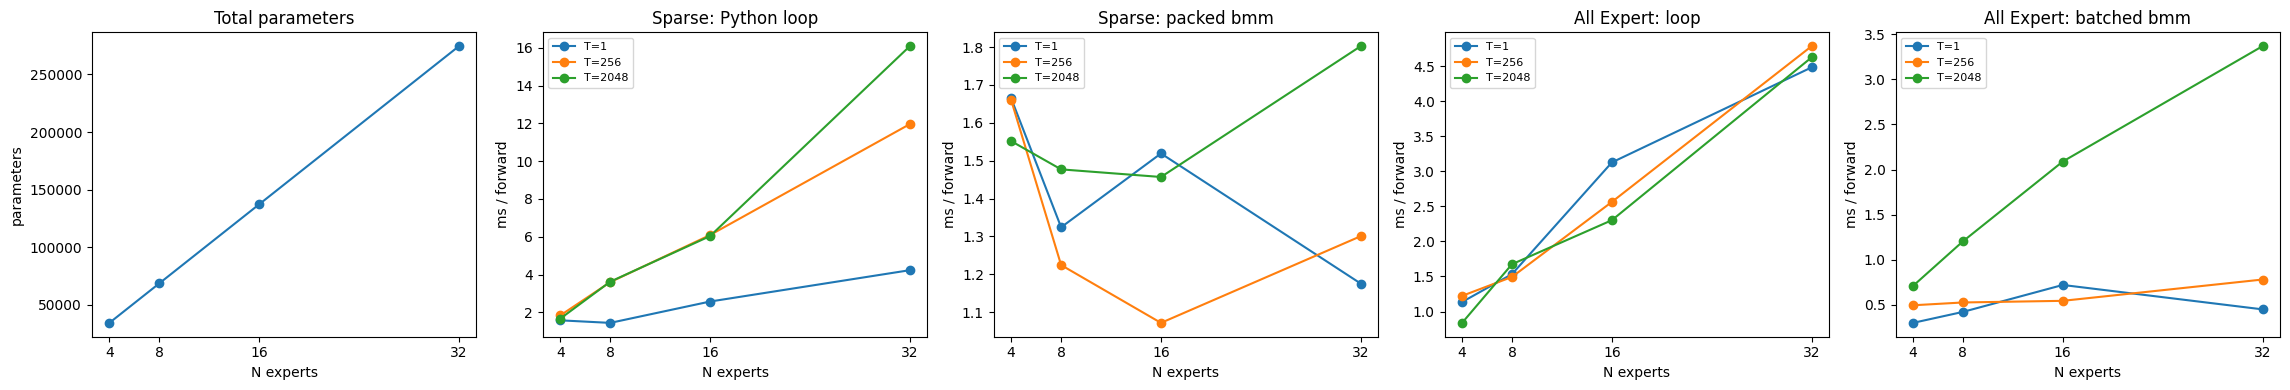

Expert MAC/token: sparse = 16640 ; all-expert = N* 8320
T=1: N=32/N=4 latency ratio: loop 2.68, packed 0.71, all 3.95; at N=32 packed/all-bmm 2.61; packed slot utilization 0.06
T=256: N=32/N=4 latency ratio: loop 6.51, packed 0.78, all 3.92; at N=32 packed/all-bmm 1.66; packed slot utilization 0.55
T=2048: N=32/N=4 latency ratio: loop 9.65, packed 1.16, all 5.53; at N=32 packed/all-bmm 0.54; packed slot utilization 0.54


In [12]:
# 参数曲线与四条推理路径的延迟曲线；横轴都只改变 Expert 数 N。
fig, axes = plt.subplots(1, 5, figsize=(23, 4))
ns = np.array(PERF_NS)
axes[0].plot(ns, [next(r for r in perf_results if r["experts"]==n)["params"] for n in ns], "o-")
axes[0].set(title="Total parameters", xlabel="N experts", ylabel="parameters", xticks=ns)

for t in PERF_TOKENS:
    rows = [r for r in perf_results if r["tokens"] == t]
    for axis, key in ((axes[1], "loop_ms"), (axes[2], "packed_ms"), (axes[3], "full_ms"), (axes[4], "all_bmm_ms")):
        axis.plot(ns, [r[key] for r in rows], "o-", label=f"T={t}")
for axis, title in ((axes[1], "Sparse: Python loop"),
                    (axes[2], "Sparse: packed bmm"),
                    (axes[3], "All Expert: loop"),
                    (axes[4], "All Expert: batched bmm")):
    axis.set(title=title, xlabel="N experts", ylabel="ms / forward", xticks=ns)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Expert MAC/token: sparse =", TOP_K*(PERF_D*PERF_H+PERF_H),
      "; all-expert = N*", PERF_D*PERF_H+PERF_H)
for t in PERF_TOKENS:
    rows = [r for r in perf_results if r["tokens"] == t]
    print(f"T={t}: N=32/N=4 latency ratio: loop {rows[-1]['loop_ms']/rows[0]['loop_ms']:.2f}, "
          f"packed {rows[-1]['packed_ms']/rows[0]['packed_ms']:.2f}, "
          f"all {rows[-1]['full_ms']/rows[0]['full_ms']:.2f}; "
          f"at N=32 packed/all-bmm {rows[-1]['packed_ms']/rows[-1]['all_bmm_ms']:.2f}; "
          f"packed slot utilization {t*TOP_K/rows[-1]['padded_slots']:.2f}")

## 8. 本次运行的结果分析

下方文字从上面保存的实测结果生成，重新执行后会同步更新；“预期”另列在最后。

In [13]:
# 分析文字从实测结果生成；速度计时受 GPU 状态影响，仅报告本次运行。
full, none = stats["Full"], stats["No balance"]
print(f"1) 实现核对：最大输出误差 {output_error:.2e}，最大梯度误差 {grad_error:.2e}；"
      f"N={MAIN_EXPERTS}, K={TOP_K} 时稀疏 Expert 路径数是全量版的 {TOP_K/MAIN_EXPERTS:.0%}。")
print(f"2) 1200 步 Full：MSE={full['mse']:.4f}，Bayes 参考={BAYES_MSE:.4f}；"
      f"clean 最大/平均负载={full['max_mean_load']:.3f}，"
      f"noisy 最大/平均负载={full['noisy_max_mean_load']:.3f}。")
print(f"   无均衡：MSE={none['mse']:.4f}，clean/noisy 最大负载比="
      f"{none['max_mean_load']:.3f}/{none['noisy_max_mean_load']:.3f}。")
for n in (4, 8, 16):
    mses = [s['mse'] for s in capacity_runs[n]]
    print(f"3) N={n}: 参数={parameter_count(capacity_models[n])}，"
          f"每 token Expert MAC={TOP_K*(D_MODEL*D_FF+D_FF)}，"
          f"三种子 MSE={statistics.mean(mses):.4f}±{statistics.stdev(mses):.4f}。")
for t in PERF_TOKENS:
    rows=[r for r in perf_results if r['tokens']==t]
    print(f"4) T={t}: N 从 4 到 32，批量打包延迟 {rows[0]['packed_ms']:.3f}→"
          f"{rows[-1]['packed_ms']:.3f} ms；批量全量 "
          f"{rows[0]['all_bmm_ms']:.3f}→{rows[-1]['all_bmm_ms']:.3f} ms；"
          f"N=32 填充利用率 {t*TOP_K/rows[-1]['padded_slots']:.1%}。")
print("结论：固定 K 时选中的 Expert 路径数不随 N 增加；任务误差与实际速度需结合"
      "多种子、噪声模式、分发实现和 batch 大小分别判断。")

1) 实现核对：最大输出误差 0.00e+00，最大梯度误差 1.49e-08；N=8, K=2 时稀疏 Expert 路径数是全量版的 25%。
2) 1200 步 Full：MSE=0.2437，Bayes 参考=0.1870；clean 最大/平均负载=1.406，noisy 最大/平均负载=1.399。
   无均衡：MSE=0.2450，clean/noisy 最大负载比=1.972/1.943。
3) N=4: 参数=572，每 token Expert MAC=224，三种子 MSE=0.2844±0.0493。
3) N=8: 参数=1144，每 token Expert MAC=224，三种子 MSE=0.2407±0.0069。
3) N=16: 参数=2288，每 token Expert MAC=224，三种子 MSE=0.2530±0.0050。
4) T=1: N 从 4 到 32，批量打包延迟 1.665→1.176 ms；批量全量 0.301→0.451 ms；N=32 填充利用率 6.2%。
4) T=256: N 从 4 到 32，批量打包延迟 1.660→1.301 ms；批量全量 0.496→0.781 ms；N=32 填充利用率 55.2%。
4) T=2048: N 从 4 到 32，批量打包延迟 1.552→1.802 ms；批量全量 0.710→3.367 ms；N=32 填充利用率 53.8%。
结论：固定 K 时选中的 Expert 路径数不随 N 增加；任务误差与实际速度需结合多种子、噪声模式、分发实现和 batch 大小分别判断。


## 9. 实验现象的预期与适用范围

运行前可提出、运行后需核对的预期：

1. 稀疏版与全量版输出及梯度应一致；实际 token–Expert 执行次数应从 $TN$ 减少到 $TK$。
2. 增加 $N$ 应增加总参数；固定 $K$ 时每 token Expert MAC 应保持不变。任务 MSE **不保证**随 $N$ 单调下降，尤其当任务已经足够简单时。
3. Full 的 noisy/clean hard load 通常比无均衡约束更均匀；无均衡版本是否完全 collapse 依赖任务和随机种子。Importance 与 load 衡量的对象不同，单独使用其中一个可能不够。
4. 逐 Expert 循环版的端到端延迟可能随 $N$ 明显上升；批量打包版更有机会接近水平，但 Router、排序、动态分发及 padding 仍会使延迟改变。批量全量版提供更公平的 GPU 算子对照；小批量下它也可能比稀疏版更快。单 token 的延迟尤其容易被固定开销主导。

**判读原则**：不把“Expert 理论计算保持不变”等同于“真实推理毫秒数不变”；以本机运行图表为准。组别路由热力图只有在整体使用仍均衡时才支持“局部分工＋全局均衡”。Dense 的参数匹配和计算匹配对照回答不同问题。论文讨论了 Expert 子批次缩小后的效率问题，因此推理速度是本实验的**测量对象**，不是预设结论。

本实验没有实现跨设备 Expert 并行、通信、容量溢出策略或大规模语言任务，结论限于单 GPU 机制验证。